# Lab 11 · Analítica longitudinal con SQL avanzado: evidencia

Este notebook acompaña a `analitica_longitudinal.sql`. **No copia números a mano:** cada celda lee la consulta
del archivo `.sql`, la ejecuta sobre `clinica.duckdb` (solo lectura) y grafica el resultado. Las celdas incluyen
`assert` con las cifras que se midieron al escribir cada actividad, de modo que si los datos o las consultas
cambian, el notebook falla en vez de mostrar una cifra distinta en silencio.

Contenido: histograma de duraciones y comparación de gaps (actividad 6), serie de HbA1c con acumulado y media
móvil (actividad 8), política sobre valores posteriores (actividad 9) y rendimiento ventana contra self-join
(actividad 10).

In [1]:
import re, statistics
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt

RUTA_SQL = Path('analitica_longitudinal.sql')
RUTA_DB  = Path('../../s10-sql-fundamentals/tu-entrega/clinica.duckdb')

con = duckdb.connect(str(RUTA_DB), read_only=True)   # solo lectura: el notebook no modifica los datos
SQL = RUTA_SQL.read_text(encoding='utf-8')

def consulta(marcador, etiqueta=None):
    """Devuelve la consulta que sigue a `marcador` en el .sql (sin comentarios de línea).

    Busca el texto `marcador`, salta a la primera línea que empieza con WITH o SELECT y
    toma hasta el primer ';' que cierra una línea.
    """
    i = SQL.index(marcador)
    m = re.compile(r'^(WITH|SELECT)\b', re.M).search(SQL, i)
    fin = re.compile(r';[ \t]*$', re.M).search(SQL, m.start())
    texto = SQL[m.start():fin.start()]
    return '\n'.join(l for l in texto.split('\n') if not l.strip().startswith('--'))

def consulta_etiquetada(etiqueta):
    """Consultas de la actividad 10, marcadas con [Q:etiqueta]."""
    return consulta(f'-- [Q:{etiqueta}]')

# Estilo sobrio y consistente para todas las figuras
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
AZUL, NARANJA, GRIS = '#1f6fb2', '#d9822b', '#7a7a7a'   # contraste suficiente; también legible en gris
print('Base:', RUTA_DB.resolve().name, '| tablas:', [t[0] for t in con.sql('SHOW TABLES').fetchall()])

Base: clinica.duckdb | tablas: ['conditions', 'encounters', 'medications', 'observations', 'patients']


## Actividad 6 · Episodios de tratamiento (gaps and islands)

Pregunta: ¿cuántos episodios continuos de tratamiento hay y cuánto duran, según el gap de persistencia (30, 60, 90
días)? Fármaco principal: **Epoetina alfa**; contraste: **lisinopril** (se probó primero y los tres gaps dan lo mismo).

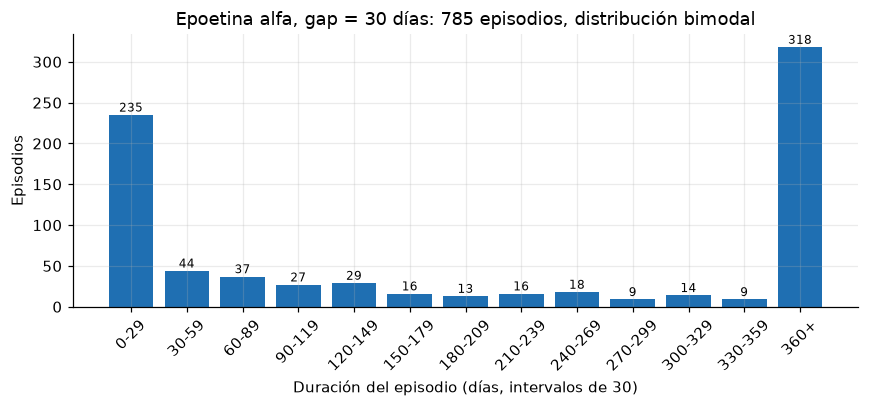

,rango_dias,n,barra
0,0-29,235,############################################
1,30-59,44,########
2,60-89,37,#######
3,90-119,27,#####
4,120-149,29,#####
5,150-179,16,###
6,180-209,13,##
7,210-239,16,###
8,240-269,18,###
9,270-299,9,##


In [2]:
hist = con.sql(consulta('-- Histograma de duraciones de episodios de Epoetina')).df()
assert hist['n'].sum() == 785, hist['n'].sum()          # 785 episodios con gap = 30
assert hist['n'].iloc[0] == 235 and hist['n'].iloc[-1] == 318

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(hist['rango_dias'], hist['n'], color=AZUL)
ax.set_xlabel('Duración del episodio (días, intervalos de 30)')
ax.set_ylabel('Episodios')
ax.set_title('Epoetina alfa, gap = 30 días: 785 episodios, distribución bimodal')
ax.tick_params(axis='x', rotation=45)
for x, n in zip(hist['rango_dias'], hist['n']):
    ax.text(x, n + 4, str(n), ha='center', fontsize=8)
plt.tight_layout(); plt.show()
hist

La distribución tiene dos grupos: **235 episodios duran menos de 30 días** (una administración aislada) y
**318 duran 360 días o más** (tratamiento sostenido); en medio hay una cola larga y pareja.

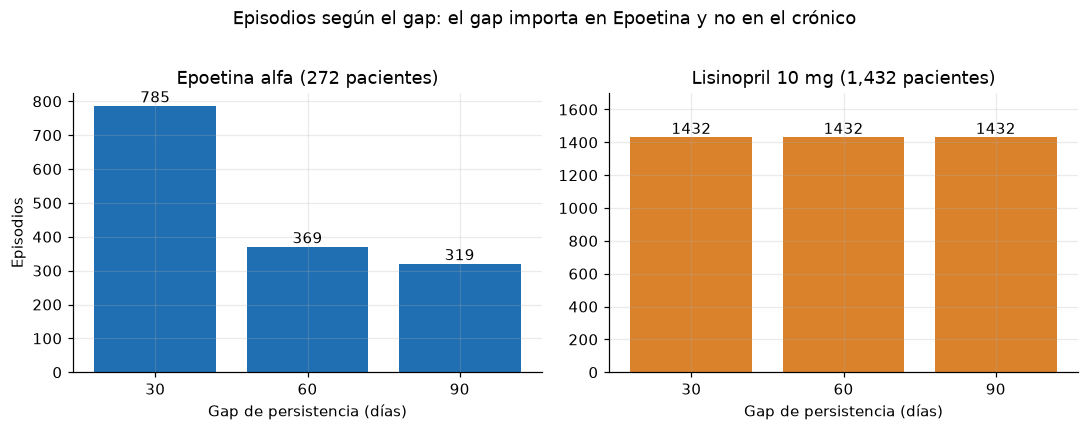

,farmaco,gap,n_episodios,n_pacientes,episodios_por_paciente,mediana_duracion_dias,recetas_cubiertas
0,1 ML Epoetin Alfa 40,30,785,272,2.89,182.0,81102.0
1,1 ML Epoetin Alfa 40,60,369,272,1.36,917.0,81102.0
2,1 ML Epoetin Alfa 40,90,319,272,1.17,1194.0,81102.0
3,lisinopril 10 MG Ora,30,1432,1432,1.00,3793.5,41278.0
4,lisinopril 10 MG Ora,60,1432,1432,1.00,3793.5,41278.0
5,lisinopril 10 MG Ora,90,1432,1432,1.00,3793.5,41278.0


In [3]:
gaps = con.sql(consulta('-- Comparación de gaps 30 / 60 / 90 para Epoetina y lisinopril')).df()
esperado = {('1 ML Epoetin Alfa 40', 30): 785, ('1 ML Epoetin Alfa 40', 60): 369, ('1 ML Epoetin Alfa 40', 90): 319,
            ('lisinopril 10 MG Ora', 30): 1432, ('lisinopril 10 MG Ora', 60): 1432, ('lisinopril 10 MG Ora', 90): 1432}
assert {(r.farmaco, r.gap): r.n_episodios for r in gaps.itertuples()} == esperado

epo = gaps[gaps['farmaco'].str.startswith('1 ML')]
lis = gaps[gaps['farmaco'].str.startswith('lisinopril')]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
a1.bar(epo['gap'].astype(str), epo['n_episodios'], color=AZUL)
a1.set_title('Epoetina alfa (272 pacientes)'); a1.set_xlabel('Gap de persistencia (días)'); a1.set_ylabel('Episodios')
for x, n in zip(epo['gap'].astype(str), epo['n_episodios']): a1.text(x, n + 12, str(n), ha='center')
a2.bar(lis['gap'].astype(str), lis['n_episodios'], color=NARANJA)
a2.set_title('Lisinopril 10 mg (1,432 pacientes)'); a2.set_xlabel('Gap de persistencia (días)')
for x, n in zip(lis['gap'].astype(str), lis['n_episodios']): a2.text(x, n + 20, str(n), ha='center')
a2.set_ylim(0, 1700)
fig.suptitle('Episodios según el gap: el gap importa en Epoetina y no en el crónico', y=1.02)
plt.tight_layout(); plt.show()
gaps

**Qué implica elegir un gap.** Con 30 días cualquier pausa corta el episodio: salen 785 episodios cortos. Con 90 días
las pausas largas se absorben: 319 episodios más largos (la mediana pasa de 182 a 1,194 días). El gap es una
convención y no un dato de los datos. En lisinopril el resultado no depende del gap (1 episodio por paciente) porque
el fármaco se prescribe de forma continua hasta el corte y las recetas largas cubren los huecos.

## Actividad 8 · Acumulado frente a media móvil (HbA1c)

Pregunta: ¿cómo difiere la media acumulada (frame por defecto) de la media móvil de 3 mediciones (frame declarado
con `ROWS`)? Paciente elegido por una regla escrita en el SQL (12 mediciones, sin fechas empatadas, al menos 4
valores distintos).

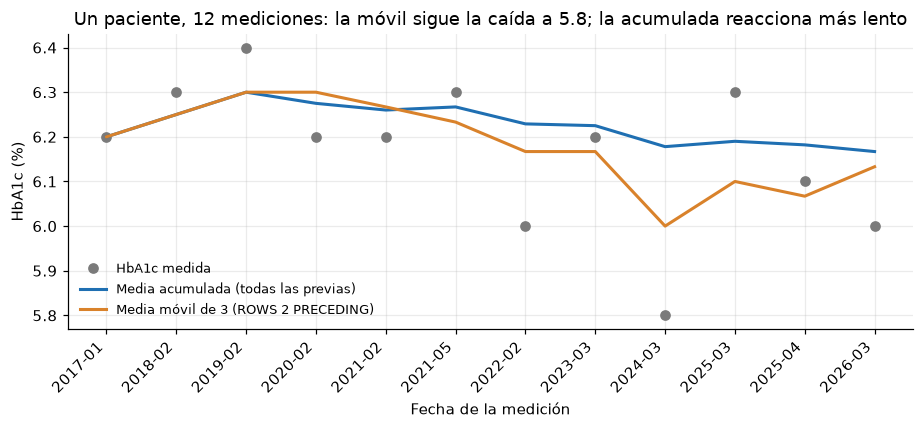

,date,valor,media_acumulada,media_acumulada_rows,media_movil_3,n_en_ventana
0,2017-01-27 07:38:16,6.2,6.200,6.200,6.200,1
1,2018-02-02 07:38:16,6.3,6.250,6.250,6.250,2
2,2019-02-08 07:38:16,6.4,6.300,6.300,6.300,3
3,2020-02-14 07:38:16,6.2,6.275,6.275,6.300,3
4,2021-02-19 07:38:16,6.2,6.260,6.260,6.267,3
5,2021-05-07 07:38:16,6.3,6.267,6.267,6.233,3
6,2022-02-25 07:38:16,6.0,6.229,6.229,6.167,3
7,2023-03-03 07:38:16,6.2,6.225,6.225,6.167,3
8,2024-03-08 07:38:16,5.8,6.178,6.178,6.000,3
9,2025-03-14 07:38:16,6.3,6.190,6.190,6.100,3


In [4]:
h = con.sql(consulta('-- Actividad 8: Acumulado')).df()
assert len(h) == 12 and h['patient'].iloc[0].startswith('05e42e38')
assert (h['media_acumulada'] == h['media_acumulada_rows']).all()   # sin empates, RANGE = ROWS

fig, ax = plt.subplots(figsize=(8.5, 4))
x = range(1, len(h) + 1)
ax.plot(x, h['valor'], 'o', color=GRIS, label='HbA1c medida')
ax.plot(x, h['media_acumulada'], '-', color=AZUL, lw=2, label='Media acumulada (todas las previas)')
ax.plot(x, h['media_movil_3'], '-', color=NARANJA, lw=2, label='Media móvil de 3 (ROWS 2 PRECEDING)')
ax.set_xticks(list(x)); ax.set_xticklabels(h['date'].dt.strftime('%Y-%m'), rotation=45, ha='right')
ax.set_ylabel('HbA1c (%)'); ax.set_xlabel('Fecha de la medición')
ax.set_title('Un paciente, 12 mediciones: la móvil sigue la caída a 5.8; la acumulada reacciona más lento')
ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()
h[['date', 'valor', 'media_acumulada', 'media_acumulada_rows', 'media_movil_3', 'n_en_ventana']]

La acumulada pesa todas las mediciones previas por igual (la medición *n* pesa 1/*n*), por eso reacciona cada vez
más lento. La móvil solo recuerda las últimas 3. En esta serie las dos columnas de acumulado coinciden porque no hay
fechas empatadas; con empates, el frame por defecto (`RANGE`) agrupa filas pares y `ROWS` no.

## Actividad 9 · Valor más cercano a la fecha índice y fuga de información

Pregunta: ¿qué HbA1c tenía cada paciente con diabetes tipo 2 alrededor de su primer diagnóstico? **Política A
(principal):** solo valores previos o del día 0. **Política B (contraste):** también valores posteriores.

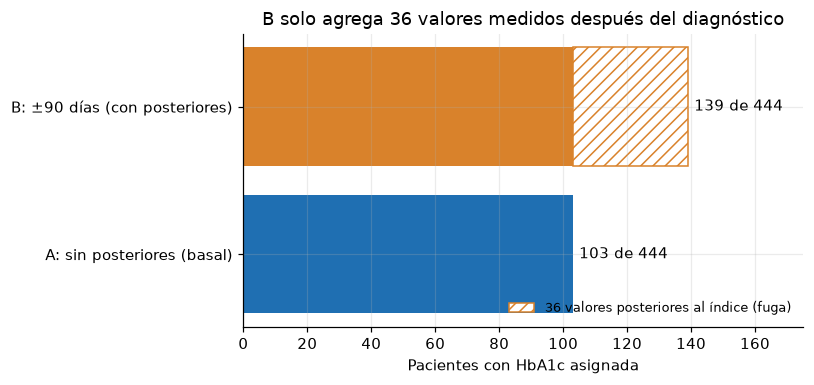

pacientes_indice           444
con_valor_politica_A       103
con_valor_politica_B       139
B_elige_posterior           36
cambian_de_valor_A_vs_B      0
A_en_dia_0                 103
Name: 0, dtype: int64

In [5]:
r = con.sql(consulta('-- Resumen A frente a B')).df().iloc[0]
assert (r.pacientes_indice, r.con_valor_politica_A, r.con_valor_politica_B, r.B_elige_posterior,
        r.cambian_de_valor_A_vs_B, r.A_en_dia_0) == (444, 103, 139, 36, 0, 103)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(['A: sin posteriores (basal)', 'B: ±90 días (con posteriores)'],
        [r.con_valor_politica_A, r.con_valor_politica_A], color=[AZUL, NARANJA])        # los mismos 103 en ambas
ax.barh(['B: ±90 días (con posteriores)'], [r.B_elige_posterior], left=[r.con_valor_politica_A],
        color='white', edgecolor=NARANJA, hatch='///', label=f'{int(r.B_elige_posterior)} valores posteriores al índice (fuga)')
for y, v in enumerate([r.con_valor_politica_A, r.con_valor_politica_B]):
    ax.text(v + 2, y, f'{int(v)} de {int(r.pacientes_indice)}', va='center')
ax.set_xlim(0, 175); ax.set_xlabel('Pacientes con HbA1c asignada')
ax.set_title('B solo agrega 36 valores medidos después del diagnóstico')
ax.legend(frameon=False, loc='lower right', fontsize=8.5)
plt.tight_layout(); plt.show()
r

Los 103 pacientes de A tienen todos la HbA1c **del día 0** (probablemente el examen que dispara el diagnóstico;
no se puede saber el orden dentro del mismo día). B asigna a esos 103 el mismo valor (0 cambios) y añade 36
pacientes cuyo único valor cercano es posterior al índice: información que ya refleja el diagnóstico y el
tratamiento. Por eso la política principal excluye valores posteriores.

## Actividad 10 · Rendimiento: ventana contra self-join

Misma pregunta que la actividad 4 (días desde la visita anterior). Se mide con `EXPLAIN ANALYZE`: 1 corrida de
calentamiento descartada y 5 corridas medidas; se reporta la mediana y el rango. DuckDB local, base en disco.

In [6]:
q = {k: consulta_etiquetada(k) for k in ['ventana', 'selfjoin', 'equivalencia', 'escala_ventana', 'escala_selfjoin']}

# 1) Mismo resultado
assert tuple(con.execute(q['ventana']).fetchall()[0])  == (429640, 5904, 12.0)
assert tuple(con.execute(q['selfjoin']).fetchall()[0]) == (429640, 5904, 12.0)
assert tuple(con.execute(q['equivalencia']).fetchall()[0]) == (429640, 429640, 0, 0)   # EXCEPT en ambos sentidos
print('Resultados idénticos: 429,640 filas, 5,904 NULL, mediana 12 días; EXCEPT en ambos sentidos = 0 filas')

# 2) Tiempos con EXPLAIN ANALYZE
def plan(sql):
    texto = con.sql('EXPLAIN ANALYZE ' + sql).fetchall()[0][1]
    return float(re.search(r'Total Time: ([\d.]+)s', texto).group(1)), texto

def medir(sql, corridas=5):
    plan(sql)                                  # calentamiento, se descarta
    return [plan(sql)[0] for _ in range(corridas)]

tiempos = {k: medir(q[k]) for k in ['ventana', 'selfjoin', 'escala_ventana', 'escala_selfjoin']}
for k, t in tiempos.items():
    print(f'{k:16s} mediana {statistics.median(t):.4f} s | rango {min(t):.4f}-{max(t):.4f} s | corridas {[round(x, 4) for x in t]}')

Resultados idénticos: 429,640 filas, 5,904 NULL, mediana 12 días; EXCEPT en ambos sentidos = 0 filas


ventana          mediana 0.0271 s | rango 0.0253-0.0426 s | corridas [0.0426, 0.0324, 0.0271, 0.0257, 0.0253]
selfjoin         mediana 0.2300 s | rango 0.2280-0.2370 s | corridas [0.228, 0.23, 0.228, 0.237, 0.234]
escala_ventana   mediana 0.0079 s | rango 0.0063-0.0118 s | corridas [0.0077, 0.0079, 0.0063, 0.0079, 0.0118]
escala_selfjoin  mediana 0.0589 s | rango 0.0549-0.0605 s | corridas [0.0549, 0.056, 0.0589, 0.0605, 0.0601]


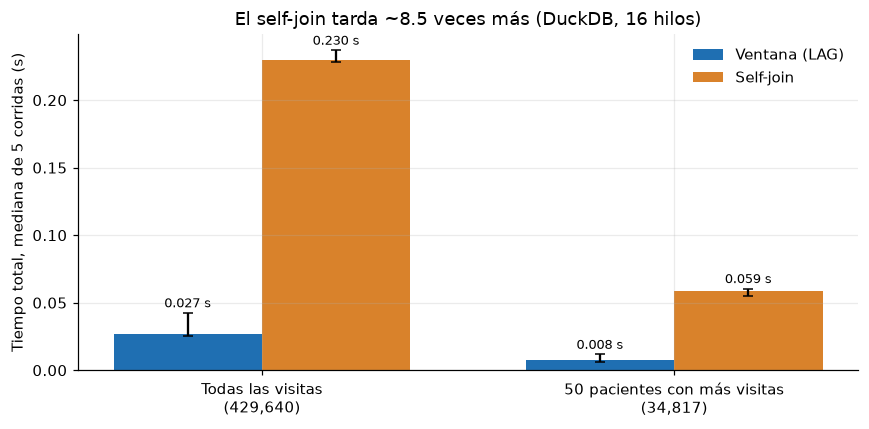

In [7]:
med = {k: statistics.median(v) for k, v in tiempos.items()}
err = {k: (med[k] - min(v), max(v) - med[k]) for k, v in tiempos.items()}
etiquetas = ['Todas las visitas\n(429,640)', '50 pacientes con más visitas\n(34,817)']
pares = [('ventana', 'selfjoin'), ('escala_ventana', 'escala_selfjoin')]

fig, ax = plt.subplots(figsize=(8, 4))
ancho = .36
for j, (nombre, color, idx) in enumerate([('Ventana (LAG)', AZUL, 0), ('Self-join', NARANJA, 1)]):
    claves = [p[idx] for p in pares]
    xs = [i + (j - .5) * ancho for i in range(2)]
    ax.bar(xs, [med[k] for k in claves], ancho, color=color, label=nombre,
           yerr=[[err[k][0] for k in claves], [err[k][1] for k in claves]], capsize=3)
    for x, k in zip(xs, claves): ax.text(x, med[k] + err[k][1] + .004, f'{med[k]:.3f} s', ha='center', fontsize=8.5)
ax.set_xticks(range(2)); ax.set_xticklabels(etiquetas)
ax.set_ylabel('Tiempo total, mediana de 5 corridas (s)')
ax.set_title(f'El self-join tarda ~{med["selfjoin"] / med["ventana"]:.1f} veces más (DuckDB, 16 hilos)')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In [8]:
# Planes de ejecución reales (una corrida cada uno). Los ms por operador son CPU sumada entre hilos;
# el tiempo comparable es 'Total Time'.
print('=== VENTANA ===');  print(plan(q['ventana'])[1])
print('=== SELF-JOIN ==='); print(plan(q['selfjoin'])[1])

=== VENTANA ===
╭─ Summary ───────────╮
│ Total Time: 0.0263s │
╰─────────────────────╯
╭─ Ungrouped Aggregate ────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Aggregates:                                                                                                          │
│ count_star(), count_star() FILTER (WHERE #0) Filter: #0, median(#1)                                                  │
│ 1 row                                                                                                         10.0ms │
╰───────────────────────────────────────────────────────────┒┎─────────────────────────────────────────────────────────╯
╭─ Projection ──────────────────────────────────────────────┚┖─────────────────────────────────────────────────────────╮
│ Projections:                                                                                                         │
│ fecha_previa IS NULL, date_diff('day', fecha_previa, fecha)    

╭─ Summary ──────────╮
│ Total Time: 0.228s │
╰────────────────────╯
╭─ CTE ──────────────────────────╮
│ CTE Name: v                    │
│ Table Index: 0                 │
│ Execution Mode: MATERIALIZED   │
│ Order Mode: BATCH_INDEX        │
│ Materialized Consumers: 2      │
│ 0 rows                  10.0ms │
╰────────────────┬───────────────╯
                 ├──────────────────────────────────────────────╮
╭─ Projection ───┴───────────────╮  ╭─ Ungrouped Aggregate ─────┴──────────────────────────╮
│ Projections: patient, id,      │  │ Aggregates:                                          │
│              start, fecha      │  │ count_star(),                                        │
│ 429,640 rows               0µs │  │ count_star() FILTER (WHERE #0) Filter: #0,           │
╰────────────────┬───────────────╯  │ median(#1)                                           │
╭─ Table Scan ───┴───────────────╮  │ 1 row                                         10.0ms │
│ Table: clinica.main.encou

In [9]:
pares_total = con.execute("""SELECT SUM(n*(n-1)/2) FROM (SELECT COUNT(*) n FROM encounters GROUP BY patient)""").fetchall()[0][0]
pares_top50 = con.execute("""SELECT SUM(n*(n-1)/2) FROM (SELECT COUNT(*) n FROM encounters GROUP BY patient
                          ORDER BY n DESC, patient LIMIT 50)""").fetchall()[0][0]
assert (pares_total, pares_top50) == (54821602, 12210619)
print(f'Pares de visitas que materializa el self-join: {pares_total:,.0f} (todos) y {pares_top50:,.0f} '
      f'(50 pacientes con más visitas, el 8 % de las filas y el {100 * pares_top50 / pares_total:.0f} % de los pares)')
print(f'Self-join: {med["escala_selfjoin"]:.3f} s -> {med["selfjoin"]:.3f} s ({med["selfjoin"] / med["escala_selfjoin"]:.1f} veces) '
      f'cuando los pares se multiplican por {pares_total / pares_top50:.1f}: su costo sigue a los pares, no a las filas.')

Pares de visitas que materializa el self-join: 54,821,602 (todos) y 12,210,619 (50 pacientes con más visitas, el 8 % de las filas y el 22 % de los pares)
Self-join: 0.059 s -> 0.230 s (3.9 veces) cuando los pares se multiplican por 4.5: su costo sigue a los pares, no a las filas.


**Conclusión.** Ambas formulaciones dan el mismo resultado y, en este conjunto, las dos son rápidas (menos de 0.25 s),
así que el rendimiento no decide por sí solo. La ventana es casi un orden de magnitud más rápida (8 a 9 veces según la corrida), más corta y más fácil de
leer. El self-join materializa 54.8 millones de pares y su costo crece con el cuadrado de las visitas por paciente;
con pacientes de miles de visitas o tablas más grandes la diferencia se amplía. **Límite:** un solo motor (DuckDB,
16 hilos) y una sola base; no se extrapola a otros motores.